# R. Tugas Praktikum 4 - NoSQL dan Pemodelan Data
**Nama:** Alfaris Aulia Rahman  
**NIM:** 2411533006

Notebook R terpisah sesuai permintaan. Format nama modul tetap `BD_P04_<NIM>_<Nama>.ipynb`; file ini berada pada folder `Tugas/` untuk membedakannya dari notebook utama. Persiapan dan benchmark K di bawah disertakan sebagai prasyarat R-1/R-4 agar Run all pada kernel baru tidak memerlukan variabel dari notebook utama. O/P/Q/S tetap berada pada notebook utama; notebook ini mengerjakan R-1 sampai R-4.

Sumber data sama kebijakannya: coba P3, lalu jalur sintetis K-1b jika gagal. Hasil waktu milik notebook R sendiri; jangan mencampurnya dengan CSV notebook utama.

## K-1. Menyiapkan Lingkungan dan Data Contoh

**Tujuan.** Memasang pustaka, membaca `trips_bersih/`, dan mengganti nama kolom menjadi nama yang mudah dibaca. Sel pertama khusus Colab; sel kedua berlaku di mana saja.

In [1]:
import importlib, subprocess, sys, os
from pathlib import Path
paket = {"duckdb":"duckdb>=1.0", "networkx":"networkx>=3.0",
         "shapely":"shapely>=2.0", "tinydb":"tinydb>=4.8",
         "deltalake":"deltalake>=1.0", "pandas":"pandas>=2.0",
         "numpy":"numpy", "pyarrow":"pyarrow>=14", "reportlab":"reportlab>=4"}
for modul, distribusi in paket.items():
    try:
        importlib.import_module(modul)
    except ImportError:
        subprocess.check_call([sys.executable,"-m","pip","install","-q",distribusi])
from IPython.display import display, Markdown
try:
    from google.colab import drive
except ImportError:
    DI_COLAB=False
else:
    DI_COLAB=True
if DI_COLAB:
    drive.mount("/content/drive")
print("Lingkungan:", "Google Colab" if DI_COLAB else "kernel lokal")
for modul in paket:
    print(modul, getattr(importlib.import_module(modul),"__version__","tersedia"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Lingkungan: Google Colab
duckdb 1.3.2
networkx 3.6.1
shapely 2.1.2
tinydb 4.9.0
deltalake 1.6.6
pandas 2.2.3
numpy 2.1.3
pyarrow 23.0.1
reportlab 5.0.1


In [2]:
import os, time, json, sqlite3, random, shutil, glob, zipfile, tempfile
import numpy as np, pandas as pd
JENIS_NOTEBOOK = "tugas"
DIR_P3 = os.environ.get("BD_P04_P3_DIR", "/content/drive/MyDrive/BigData/Praktikum3")
DIR_SIMPAN = ("/content/drive/MyDrive/BigData/Praktikum4/Tugas" if DI_COLAB
              else os.environ.get("BD_P04_OUTPUT_DIR", str(Path.cwd())))
WORKDIR = Path(os.environ.get("BD_P04_WORKDIR",
               "/content/p04_runtime" if DI_COLAB else str(Path.cwd()/"work"/"p04_runtime")))
WORKDIR.mkdir(parents=True,exist_ok=True)
Path(DIR_SIMPAN).mkdir(parents=True,exist_ok=True)
PATH_SQLITE=str(WORKDIR/"uji.db")
PATH_BARIS=str(WORKDIR/"baris.db")
TRIPS_BERSIH=f"{DIR_P3}/trips_bersih"

# K-1b: generator cadangan dari modul, dimasukkan agar runtime baru mandiri.
def bangkitkan_trips_sintetis(keluar,n=1_000_000,seed=42):
    rng=np.random.default_rng(seed)
    wilayah=["Manhattan","Brooklyn","Queens","Bronx","Staten Island","EWR"]
    zona_ids=np.arange(1,264)
    wilayah_zona=rng.choice(wilayah,size=len(zona_ids),p=[0.35,0.25,0.22,0.10,0.05,0.03])
    zona=pd.DataFrame({"LocationID":zona_ids,"borough_naik":wilayah_zona})
    pop=np.clip(rng.zipf(1.6,size=len(zona_ids)).astype(float),1,60)
    pop/=pop.sum()
    pu=rng.choice(zona_ids,size=n,p=pop)
    do=rng.choice(zona_ids,size=n,p=pop)
    awal=pd.Timestamp("2023-01-01")
    pickup=awal+pd.to_timedelta(rng.integers(0,31*24*60,n),unit="m")
    durasi=rng.integers(2,90,n)
    dist=np.round(rng.gamma(2.0,1.6,n).clip(0.05,60),2)
    fare=np.round(2.5+dist*2.8+rng.gamma(2.0,1.0,n),2)
    tip=np.round(rng.gamma(1.5,1.2,n),2)
    pay=rng.choice([1,2,3,4],size=n,p=[0.7,0.27,0.02,0.01])
    d=pd.DataFrame({
        "tpep_pickup_datetime":pickup,
        "tpep_dropoff_datetime":pickup+pd.to_timedelta(durasi,unit="m"),
        "passenger_count":rng.integers(1,5,n).astype("float64"),
        "trip_distance":dist,"PULocationID":pu,"DOLocationID":do,
        "payment_type":pay,"fare_amount":fare,"tip_amount":tip,
        "total_amount":np.round(fare+tip+3.0,2),"durasi_menit":durasi.astype("float64"),
        "nama_pembayaran":pd.Series(pay).map({1:"Kartu kredit",2:"Tunai",3:"Gratis",4:"Sengketa"}).values})
    d=d.merge(zona.rename(columns={"LocationID":"PULocationID"}),on="PULocationID",how="left")
    d["suhu_c"]=np.round(rng.normal(3,5,n),1)
    d["hujan_mm"]=np.round(rng.gamma(0.4,0.8,n),2)
    if os.path.exists(keluar):
        shutil.rmtree(keluar)
    d.to_parquet(keluar,partition_cols=["borough_naik"],index=False)
    return str(keluar)

catatan=[]
waktu_tepat={}
def ukur(label,fungsi):
    t0=time.perf_counter()
    hasil=fungsi()
    detik=time.perf_counter()-t0
    catatan.append({"langkah":label,"detik":round(detik,4)})
    waktu_tepat[label]=detik
    print(f"[{label}] {detik:.4f} s")
    return hasil

try:
    # ZIP hanya diekstrak jika folder Parquet belum tersedia; tidak menulis ke P3.
    if not glob.glob(f"{TRIPS_BERSIH}/**/*.parquet",recursive=True):
        arsip=Path(DIR_P3)/"trips_bersih.zip"
        if arsip.is_file():
            lokal=Path(tempfile.mkdtemp(prefix="p3_asli_",dir=WORKDIR))
            with zipfile.ZipFile(arsip) as z:
                z.extractall(lokal)
            TRIPS_BERSIH=str(lokal)
    df=ukur("baca trips_bersih",lambda:pd.read_parquet(TRIPS_BERSIH))
    if not glob.glob(f"{TRIPS_BERSIH}/*/*.parquet"):
        raise ValueError("Struktur folder tidak cocok dengan glob K-4 modul")
    SUMBER_DATA="asli P3"
except Exception as e:
    print(f"Data P3 belum dapat dibaca: {type(e).__name__}: {e}")
    print("Menggunakan jalur cadangan K-1b modul; data perjalanan adalah sintetis.")
    TRIPS_BERSIH=bangkitkan_trips_sintetis(WORKDIR/"trips_bersih_sintetis")
    df=ukur("baca trips_bersih (sintetis)",lambda:pd.read_parquet(TRIPS_BERSIH))
    SUMBER_DATA="sintetis K-1b (seed 42)"

NAMA_BARU={"tpep_pickup_datetime":"waktu_jemput","PULocationID":"zona_jemput",
           "DOLocationID":"zona_tujuan","borough_naik":"wilayah_jemput",
           "trip_distance":"jarak_mil","total_amount":"total_bayar",
           "tip_amount":"tip","nama_pembayaran":"metode_bayar"}
assert set(NAMA_BARU)<=set(df.columns),"Kolom wajib K-1 tidak lengkap"
df=df.rename(columns=NAMA_BARU)
df["wilayah_jemput"]=df["wilayah_jemput"].astype(str)
assert len(df)>=200_000,"Sel K-7/K-8 modul memerlukan setidaknya 200.000 baris"
print("Sumber:",SUMBER_DATA)
print("baris:",f"{len(df):,}","| kolom:",df.shape[1])
sample=df.sample(n=min(300_000,len(df)),random_state=42).reset_index(drop=True)
sample["id_perjalanan"]=sample.index+1
sample["waktu_jemput"]=sample["waktu_jemput"].astype(str)
def jawab(teks):
    display(Markdown(teks))
def detik(label):
    return next(r["detik"] for r in catatan if r["langkah"]==label)
def banding_waktu(label_a,label_b):
    a,b=detik(label_a),detik(label_b)
    return a/b if b else float("nan")

Data P3 belum dapat dibaca: ArrowInvalid: Cannot yet unify dictionaries with nulls
Menggunakan jalur cadangan K-1b modul; data perjalanan adalah sintetis.
[baca trips_bersih (sintetis)] 0.8074 s
Sumber: sintetis K-1b (seed 42)
baris: 1,000,000 | kolom: 15


## K-2. Tabel Biasa vs Key-value

**Tujuan.** Menyimpan perjalanan yang sama dalam dua cara, lalu mengajukan dua pertanyaan berbeda. Cara pertama: tabel SQLite. Cara kedua: key-value, yaitu kamus Python yang kuncinya “perjalanan:<id>” dan nilainya teks JSON.

**Prediksi sebelum run baru.** Untuk 200 ID, key-value diperkirakan sekitar 2-4 kali lebih cepat daripada SQL berindeks; indeks diperkirakan 500-1500 kali lebih cepat daripada scan. Pada agregasi 300.000 baris, SQL diperkirakan 5-10 kali lebih cepat daripada membuka seluruh JSON.

In [3]:
KOLOM = ["id_perjalanan", "waktu_jemput", "zona_jemput", "zona_tujuan",
         "wilayah_jemput", "jarak_mil", "total_bayar", "metode_bayar"]
data = sample[KOLOM].copy()
# Model 1 - relasional: tabel SQLite
if os.path.exists(PATH_SQLITE):
    os.remove(PATH_SQLITE)
con = sqlite3.connect(PATH_SQLITE)
ukur("relasional: muat tabel", lambda: data.to_sql("perjalanan", con, index=False))
# Model 2 - key-value: kamus (dict) dengan kunci "perjalanan:<id>", nilainya teks JSON
def bangun_kv():
    return {f"perjalanan:{r['id_perjalanan']}": json.dumps(r) for r in data.to_dict("records")}
kv = ukur("key-value: bangun dict", bangun_kv)
print("jumlah key:", len(kv))
# Pertanyaan A: ambil SATU perjalanan berdasarkan id (200 id acak)
random.seed(42)
id_uji = random.sample(range(1, len(data) + 1), 200)
def cari_sql():
    cur = con.cursor()
    return [cur.execute("SELECT * FROM perjalanan WHERE id_perjalanan = ?", (i,)).fetchone() for i in id_uji]
def cari_kv():
    return [json.loads(kv[f"perjalanan:{i}"]) for i in id_uji]
r1 = ukur("cari 200 perjalanan - SQL tanpa indeks", cari_sql)
con.execute("CREATE INDEX idx_id ON perjalanan(id_perjalanan)") # buat indeks
r2 = ukur("cari 200 perjalanan - SQL dengan indeks", cari_sql)
r3 = ukur("cari 200 perjalanan - key-value", cari_kv)
print("hasil sama?", r1[0][0] == r2[0][0] == r3[0]["id_perjalanan"])
# Pertanyaan B: hitung rata-rata total bayar per wilayah (melibatkan SEMUA data)
def hitung_sql():
    return con.execute("""SELECT wilayah_jemput, COUNT(*), ROUND(AVG(total_bayar), 2)
    FROM perjalanan GROUP BY wilayah_jemput ORDER BY 2 DESC, 1""").fetchall()
def hitung_kv():
    total, jumlah = {}, {}
    for teks in kv.values():
        d = json.loads(teks) # setiap nilai harus dibuka dulu
        w = d["wilayah_jemput"]
        total[w] = total.get(w, 0) + d["total_bayar"]
        jumlah[w] = jumlah.get(w, 0) + 1
    return sorted([(w, jumlah[w], round(total[w] / jumlah[w], 2)) for w in jumlah],
                  key=lambda x: (-x[1], x[0]))
h1 = ukur("hitung per wilayah - SQL GROUP BY", hitung_sql)
h2 = ukur("hitung per wilayah - key-value (buka semua nilai)", hitung_kv)
print(h1[:3])
print("hasil sama?", h1 == h2)
assert r1 == r2
assert [dict(zip(KOLOM,r)) for r in r2] == r3
assert h1 == h2


[relasional: muat tabel] 1.2786 s
[key-value: bangun dict] 3.1270 s
jumlah key: 300000
[cari 200 perjalanan - SQL tanpa indeks] 6.8203 s
[cari 200 perjalanan - SQL dengan indeks] 0.0048 s
[cari 200 perjalanan - key-value] 0.0011 s
hasil sama? True
[hitung per wilayah - SQL GROUP BY] 0.2094 s
[hitung per wilayah - key-value (buka semua nilai)] 1.4247 s
[('Manhattan', 116930, 18.26), ('Queens', 81377, 18.29), ('Brooklyn', 62038, 18.24)]
hasil sama? True


## K-3. Document: Bentuk Data yang Fleksibel

**Tujuan.** Menyimpan perjalanan sebagai dokumen JSON bersarang, lalu melihat dua hal: data terkait dibungkus dalam satu dokumen (embedding), dan field tip sengaja hanya ada pada pembayaran kartu, mirip data TLC asli yang tidak mencatat tip tunai.

**Prediksi sebelum run baru.** Sebanyak 20.000 dokumen awal dapat mempunyai field opsional berbeda. Setelah satu dokumen cuaca ditambahkan, jumlah diperkirakan 20.001; perubahan ini dinilai kualitatif, bukan rasio kecepatan.

In [4]:
from tinydb import TinyDB, Query
from tinydb.storages import MemoryStorage
def ke_dokumen(r):
    dok = {
        "id_perjalanan": int(r.id_perjalanan),
        "waktu_jemput": r.waktu_jemput,
        "jemput": {"zona": int(r.zona_jemput), "wilayah": r.wilayah_jemput},
        "tujuan": {"zona": int(r.zona_tujuan)},
        "biaya": {"jarak_mil": float(r.jarak_mil),
                  "total": float(r.total_bayar),
                  "metode_bayar": r.metode_bayar},
    }
    # Tip hanya dicatat untuk pembayaran kartu -> field ini ada di sebagian dokumen saja
    if r.metode_bayar == "Kartu kredit":
        dok["biaya"]["tip"] = float(r.tip)
    return dok
db = TinyDB(storage=MemoryStorage)
tabel = db.table("perjalanan")
docs = [ke_dokumen(r) for r in sample.head(20_000).itertuples()]
tabel.insert_multiple(docs)
print("jumlah dokumen:", len(tabel))
print(json.dumps(tabel.all()[0], indent=2))

jumlah dokumen: 20000
{
  "id_perjalanan": 1,
  "waktu_jemput": "2023-01-10 17:57:00",
  "jemput": {
    "zona": 219,
    "wilayah": "Staten Island"
  },
  "tujuan": {
    "zona": 46
  },
  "biaya": {
    "jarak_mil": 2.0,
    "total": 17.99,
    "metode_bayar": "Kartu kredit",
    "tip": 4.81
  }
}


In [5]:
Q = Query()
print("jemput di Manhattan & total > 50 :", len(tabel.search((Q.jemput.wilayah == "Manhattan") &
                                                              (Q.biaya.total > 50))))
print("dokumen yang punya field tip :", len(tabel.search(Q.biaya.tip.exists())))
print("dokumen yang TIDAK punya tip :", len(tabel.search(~Q.biaya.tip.exists())))
# Menambah field baru ("cuaca") pada satu dokumen - tanpa mengubah struktur apa pun
tabel.insert({"id_perjalanan": 999_999, "waktu_jemput": "2023-01-15 08:00:00",
              "jemput": {"zona": 161, "wilayah": "Manhattan"}, "tujuan": {"zona": 236},
              "biaya": {"jarak_mil": 1.2, "total": 14.5, "metode_bayar": "Kartu kredit", "tip": 3.0},
              "cuaca": {"hujan": True, "suhu_c": -2.0}})
print("dokumen yang punya field cuaca :", len(tabel.search(Q.cuaca.exists())))
print("total dokumen sekarang :", len(tabel))

jemput di Manhattan & total > 50 : 9
dokumen yang punya field tip : 13979
dokumen yang TIDAK punya tip : 6021
dokumen yang punya field cuaca : 1
total dokumen sekarang : 20001


## K-4. Penyimpanan per Kolom: DuckDB pada Parquet

**Tujuan.** Menjalankan SQL langsung pada folder Parquet berpartisi tanpa memuatnya ke tabel dulu, lalu membandingkannya dengan SQLite (penyimpanan per baris) untuk perhitungan yang sama. View pada kode ini adalah “jendela” bernama di atas file Parquet; data tidak disalin.

**Prediksi sebelum run baru.** Pada agregasi satu juta baris, DuckDB diperkirakan 5-20 kali lebih cepat daripada SQLite. Query satu partisi diperkirakan lebih cepat daripada seluruh wilayah.

In [6]:
import duckdb
GLOB = f"{TRIPS_BERSIH}/*/*.parquet"
con_d = duckdb.connect()
# VIEW = "jendela" bernama yang membaca Parquet langsung (tidak menyalin data).
# Di sinilah nama kolom asli TLC diberi nama yang mudah dibaca.
con_d.sql(f"""
CREATE VIEW perjalanan AS
SELECT tpep_pickup_datetime AS waktu_jemput,
       PULocationID AS zona_jemput,
       DOLocationID AS zona_tujuan,
       borough_naik AS wilayah_jemput,
       trip_distance AS jarak_mil,
       total_amount AS total_bayar,
       nama_pembayaran AS metode_bayar
FROM read_parquet('{GLOB}', hive_partitioning=true)""")
SQL = """SELECT wilayah_jemput, COUNT(*) AS jumlah, ROUND(AVG(total_bayar), 2) AS rata_bayar
FROM perjalanan GROUP BY wilayah_jemput ORDER BY jumlah DESC, wilayah_jemput"""
hasil_d = ukur("DuckDB - hitung per wilayah (langsung dari Parquet)", lambda: con_d.sql(SQL).df())
print(hasil_d)
# Pembanding: SQLite (menyimpan per baris) pada data yang sama
KOLOM_S = ["wilayah_jemput", "total_bayar", "jarak_mil", "zona_jemput", "zona_tujuan"]
if os.path.exists(PATH_BARIS):
    os.remove(PATH_BARIS)
con_s = sqlite3.connect(PATH_BARIS)
ukur("SQLite - muat seluruh baris ke tabel", lambda: df[KOLOM_S].to_sql("perjalanan", con_s, index=False))
hasil_s = ukur("SQLite - hitung per wilayah", lambda: con_s.execute(
    """SELECT wilayah_jemput, COUNT(*), ROUND(AVG(total_bayar), 2)
    FROM perjalanan GROUP BY wilayah_jemput ORDER BY 2 DESC, 1""").fetchall())
print("hasil sama?", [tuple(r) for r in hasil_d.itertuples(index=False)] == [tuple(r) for r in hasil_s])
assert [tuple(r) for r in hasil_d.itertuples(index=False)] == [tuple(r) for r in hasil_s]
assert int(hasil_d["jumlah"].sum()) == len(df)


[DuckDB - hitung per wilayah (langsung dari Parquet)] 0.0319 s
  wilayah_jemput  jumlah  rata_bayar
0      Manhattan  391107       18.26
1         Queens  270929       18.27
2       Brooklyn  205487       18.29
3  Staten Island   67041       18.28
4          Bronx   60912       18.21
5            EWR    4524       18.31
[SQLite - muat seluruh baris ke tabel] 2.2082 s
[SQLite - hitung per wilayah] 0.6151 s
hasil sama? True


In [7]:
# Filter pada kolom partisi: DuckDB hanya membuka folder wilayah yang diminta (partition pruning, P3)
SQL2 = """SELECT COUNT(*), ROUND(AVG(total_bayar), 2)
FROM perjalanan WHERE wilayah_jemput = 'Staten Island'"""
print(ukur("DuckDB - hanya wilayah Staten Island", lambda: con_d.sql(SQL2).fetchall()))
ukuran_pq = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(TRIPS_BERSIH) for f in fs) / 1024**2
print(f"Parquet ({df.shape[1]} kolom): {ukuran_pq:.1f} MB | SQLite ({len(KOLOM_S)} kolom): {os.path.getsize(PATH_BARIS) / 1024**2:.1f} MB")

[DuckDB - hanya wilayah Staten Island] 0.0130 s
[(67041, 18.28)]
Parquet (15 kolom): 32.2 MB | SQLite (5 kolom): 37.6 MB


## K-5. Graph: Pertanyaan tentang Keterhubungan

**Tujuan.** Meringkas perjalanan menjadi arus antar zona. Setiap zona adalah node, dan setiap pasangan zona asal-tujuan adalah edge berarah dengan bobot jumlah perjalanan. Hasil graph disilangkan dengan SQL agar kita yakin keduanya menjawab hal yang sama.

**Prediksi sebelum run baru.** Untuk dua langkah pada graph kecil, kedua cara diperkirakan berorde milidetik dan berbeda kurang dari 3 kali. Keuntungan graph terutama kemudahan mengganti batas k.

In [8]:
import networkx as nx
# Satu baris = satu arus: berapa perjalanan dari zona jemput ke zona tujuan tertentu
arus = ukur("hitung arus antar zona", lambda: con_d.sql("""
SELECT zona_jemput AS asal, zona_tujuan AS tujuan, COUNT(*) AS jumlah
FROM perjalanan GROUP BY 1, 2""").df())
# Zona = node (titik), arus = edge (garis berarah, bobotnya jumlah perjalanan)
G = nx.DiGraph()
for r in arus.itertuples(index=False):
    G.add_edge(int(r.asal), int(r.tujuan), jumlah=int(r.jumlah))
print("node (zona):", G.number_of_nodes(), "| edge (arus):", G.number_of_edges())
# Lima arus terbesar. Urutan dibuat pasti dengan pengurut tambahan (jumlah, asal, tujuan)
top_graf = sorted(G.edges(data=True), key=lambda e: (-e[2]["jumlah"], e[0], e[1]))[:5]
print("graph:", [(a, b, d["jumlah"]) for a, b, d in top_graf])
top_sql = arus.sort_values(["jumlah", "asal", "tujuan"], ascending=[False, True, True]).head(5)
print("SQL :", list(top_sql.itertuples(index=False, name=None)))
# Lima zona yang paling banyak menjadi tujuan
populer = sorted(G.in_degree(weight="jumlah"), key=lambda kv: (-kv[1], kv[0]))[:5]
print("zona tujuan terpopuler:", populer)

[hitung arus antar zona] 0.0770 s
node (zona): 263 | edge (arus): 44120
graph: [(46, 205, 789), (146, 129, 787), (74, 221, 765), (221, 166, 765), (46, 221, 761)]
SQL : [(46, 205, 789), (146, 129, 787), (74, 221, 765), (221, 166, 765), (46, 221, 761)]
zona tujuan terpopuler: [(183, 26941), (104, 26916), (146, 26891), (164, 26867), (194, 26847)]


In [9]:
MIN = 50 # abaikan arus yang terlalu jarang (kurang dari 50 perjalanan)
zona_awal = populer[0][0] # mulai dari zona tujuan terpopuler
# Pertanyaan: zona mana yang bisa dicapai dalam TEPAT 2 langkah dari zona_awal?
# (1) cara graph: telusuri tetangga dari tetangga
def dua_langkah_graph():
    hasil = set()
    for b, d1 in G[zona_awal].items():
        if d1["jumlah"] < MIN:
            continue
        for c, d2 in G[b].items():
            if d2["jumlah"] >= MIN and c != zona_awal:
                hasil.add(c)
    return hasil
# (2) cara SQL: harus menggabungkan tabel arus dengan dirinya sendiri (self-join)
con_d.register("arus", arus)
def dua_langkah_sql():
    return set(con_d.sql(f"""
    SELECT DISTINCT a2.tujuan
    FROM arus a1 JOIN arus a2 ON a1.tujuan = a2.asal
    WHERE a1.asal = {zona_awal} AND a1.jumlah >= {MIN}
    AND a2.jumlah >= {MIN} AND a2.tujuan <> {zona_awal}""").df()["tujuan"])
hg = ukur("2 langkah - graph (NetworkX)", dua_langkah_graph)
hs = ukur("2 langkah - SQL self-join (DuckDB)", dua_langkah_sql)
print("zona awal:", zona_awal, "| terjangkau (graph):", len(hg), "| (SQL):", len(hs), "| sama?", hg == hs)
# (3) Jumlah langkah bebas: "dalam paling banyak k langkah" - cukup ganti angka k
H = nx.DiGraph([(a, b) for a, b, d in G.edges(data=True) if d["jumlah"] >= MIN])
for k in (1, 2, 3, 4):
    n = len(nx.single_source_shortest_path_length(H, zona_awal, cutoff=k)) - 1
    print(f"dalam <= {k} langkah: {n} zona")
assert hg == hs
jangkauan = {k: len(nx.single_source_shortest_path_length(H,zona_awal,cutoff=k))-1 for k in (1,2,3,4)}


[2 langkah - graph (NetworkX)] 0.0173 s
[2 langkah - SQL self-join (DuckDB)] 0.0055 s
zona awal: 183 | terjangkau (graph): 91 | (SQL): 91 | sama? True
dalam <= 1 langkah: 83 zona
dalam <= 2 langkah: 91 zona
dalam <= 3 langkah: 91 zona
dalam <= 4 langkah: 91 zona


## K-6. Indeks Spasial

**Tujuan.** Mencari titik jemput di dalam 1.000 kotak kecil (sekitar 1 km × 1 km) dengan tiga cara: loop Python, NumPy tanpa indeks spasial, dan indeks STRtree. Cara pertama hanya dijalankan untuk 5 kotak karena terlalu lambat.

**Prediksi sebelum run baru.** STRtree untuk 1.000 kotak diperkirakan 2-5 kali lebih cepat daripada NumPy untuk query saja. Rasio menurun bila pembangunan indeks dihitung. Loop 5 kotak harus dibandingkan pada jumlah kotak yang sama.

In [10]:
from shapely import STRtree, box, points
# CATATAN: data TLC 2023 hanya berisi ID zona, TANPA koordinat. Titik di bawah ini SINTETIS.
rng = np.random.default_rng(42)
N = 200_000
bujur = rng.normal(-73.97, 0.06, N).clip(-74.25, -73.70) # longitude
lintang = rng.normal(40.74, 0.05, N).clip(40.50, 40.92) # latitude
titik = points(bujur, lintang)
# 1.000 wilayah pencarian berupa kotak kecil (sekitar 1 km x 1 km)
M = 1000
cx = rng.uniform(-74.05, -73.85, M)
cy = rng.uniform(40.65, 40.85, M)
kotak = [box(x - 0.005, y - 0.005, x + 0.005, y + 0.005) for x, y in zip(cx, cy)]
# Cara 1: periksa titik satu per satu dengan loop Python (hanya 5 kotak, 1.000 akan sangat lama)
def cara_loop():
    return [sum(1 for p in titik if k.contains(p)) for k in kotak[:5]]
# Cara 2: bandingkan seluruh titik sekaligus dengan NumPy (tanpa indeks spasial), 1.000 kotak
def cara_numpy():
    hasil = []
    for x, y in zip(cx, cy):
        m = (bujur >= x - 0.005) & (bujur <= x + 0.005) & (lintang >= y - 0.005) & (lintang <= y + 0.005)
        hasil.append(int(m.sum()))
    return hasil
h_loop = ukur("cara 1 - loop Python, 5 kotak", cara_loop)
h_np = ukur("cara 2 - NumPy, 1000 kotak", cara_numpy)
# Cara 3: indeks spasial STRtree (sejenis R-tree)
pohon = ukur("bangun indeks STRtree", lambda: STRtree(titik))
h_idx = ukur("cara 3 - STRtree, 1000 kotak",
             lambda: [len(pohon.query(k, predicate="contains")) for k in kotak])
print("5 kotak pertama - loop:", h_loop, "| STRtree:", h_idx[:5])
print("hasil NumPy dan STRtree sama?", h_np == h_idx, "| loop dan STRtree sama (5 pertama)?", h_loop == h_idx[:5])
print("total titik ditemukan (1000 kotak):", sum(h_idx))
assert h_np == h_idx and h_loop == h_idx[:5]


[cara 1 - loop Python, 5 kotak] 13.5701 s
[cara 2 - NumPy, 1000 kotak] 0.5554 s
[bangun indeks STRtree] 0.0754 s
[cara 3 - STRtree, 1000 kotak] 0.2964 s
5 kotak pertama - loop: [1012, 84, 228, 748, 509] | STRtree: [1012, 84, 228, 748, 509]
hasil NumPy dan STRtree sama? True | loop dan STRtree sama (5 pertama)? True
total titik ditemukan (1000 kotak): 417545


## K-7. Delta Lake: Versi, Time Travel, dan Schema Enforcement

**Tujuan.** Menjawab tiga pertanyaan dari Praktikum 3/K-8. Tabel Delta dibuat, ditambah data, lalu dikoreksi dengan update; setelah itu kita menelusuri versinya.

**Prediksi sebelum run baru.** Versi 0/1/2 diperkirakan berisi 100.000/150.000/150.000 baris. Koreksi menambah total sebesar jumlah baris yang terkena, dan append kolom asing harus ditolak.

In [11]:
from deltalake import DeltaTable, write_deltalake
KOLOM_DELTA = ["waktu_jemput", "zona_jemput", "zona_tujuan",
               "wilayah_jemput", "jarak_mil", "total_bayar", "metode_bayar"]
data_delta = df[KOLOM_DELTA].sample(n=min(200_000, len(df)),
                                   random_state=42).reset_index(drop=True)
# Delta dikerjakan pada runtime lokal dan diarsipkan setelah seluruh langkah selesai.
PATH_DELTA = str(WORKDIR / "trips_delta")
if os.path.exists(PATH_DELTA):
    shutil.rmtree(PATH_DELTA)
# Versi 0: menulis data awal (100.000 baris)
write_deltalake(PATH_DELTA, data_delta.iloc[:100_000], mode="overwrite")
dt = DeltaTable(PATH_DELTA)
print("versi:", dt.version(), "| baris:", len(dt.to_pandas()))
# Versi 1: menambah 50.000 baris
write_deltalake(PATH_DELTA, data_delta.iloc[100_000:150_000], mode="append")
dt = DeltaTable(PATH_DELTA)
print("versi:", dt.version(), "| baris:", len(dt.to_pandas()))
# Versi 2: koreksi data. Anggap tarif Tunai di wilayah Bronx perlu ditambah 1.0
sekarang = data_delta.iloc[:150_000]
n_koreksi = int(((sekarang["wilayah_jemput"] == "Bronx") & (sekarang["metode_bayar"] == "Tunai")).sum())
print("baris yang akan dikoreksi:", n_koreksi)
dt.update(predicate="wilayah_jemput = 'Bronx' AND metode_bayar = 'Tunai'",
          updates={"total_bayar": "total_bayar + 1.0"})
print("versi:", DeltaTable(PATH_DELTA).version())

versi: 0 | baris: 100000
versi: 1 | baris: 150000
baris yang akan dikoreksi: 2517
versi: 2


In [12]:
# TIME TRAVEL: baca tabel sebagaimana keadaannya pada versi tertentu
v0 = DeltaTable(PATH_DELTA, version=0).to_pandas()
v1 = DeltaTable(PATH_DELTA, version=1).to_pandas()
terbaru = DeltaTable(PATH_DELTA).to_pandas()
print("baris v0:", len(v0), "| v1:", len(v1), "| terbaru:", len(terbaru))
selisih = terbaru["total_bayar"].sum() - v1["total_bayar"].sum()
print("selisih total_bayar (terbaru - v1):", round(selisih, 2), "| jumlah baris dikoreksi:", n_koreksi)
# Riwayat perubahan tabel
for h in DeltaTable(PATH_DELTA).history():
    print(h.get("version"), h.get("operation"))
# Log transaksi: satu file JSON per versi
print(sorted(os.listdir(f"{PATH_DELTA}/_delta_log")))
# PENEGAKAN SKEMA: menambah data dengan kolom asing harus DITOLAK, tabel tidak berubah
tambahan = data_delta.iloc[150_000:150_010].copy()
tambahan["kolom_asing"] = 1
try:
    write_deltalake(PATH_DELTA, tambahan, mode="append")
    print("append kolom asing: BERHASIL (tidak diharapkan)")
except Exception as e:
    print("append kolom asing DITOLAK:", type(e).__name__)
print("versi setelah percobaan gagal:", DeltaTable(PATH_DELTA).version())
assert len(v0)==100_000 and len(v1)==150_000 and len(terbaru)==150_000
assert np.isclose(selisih,n_koreksi)
assert DeltaTable(PATH_DELTA).version()==2
bukti_k7={"versi":2,"baris_v0":len(v0),"baris_v1":len(v1),
          "baris_v2":len(terbaru),"koreksi":n_koreksi,"selisih":float(selisih)}


baris v0: 100000 | v1: 150000 | terbaru: 150000
selisih total_bayar (terbaru - v1): 2517.0 | jumlah baris dikoreksi: 2517
2 UPDATE
1 WRITE
0 WRITE
['00000000000000000000.json', '00000000000000000001.json', '00000000000000000002.json']
append kolom asing DITOLAK: SchemaMismatchError
versi setelah percobaan gagal: 2


## K-8. Small File Problem pada Tabel Delta

**Tujuan.** Meniru data yang masuk sedikit demi sedikit (menghasilkan banyak file kecil, seperti Praktikum 3/K-6), lalu merapikannya dengan compaction.

**Prediksi sebelum run baru.** Dua puluh append kecil diperkirakan menaikkan file aktif dari 1 ke 21; compact menurunkannya ke 1 tanpa mengubah baris. Pembacaan setelah compact diperkirakan sedikit lebih cepat, tetapi hasil tunggal dapat dipengaruhi cache.

In [13]:
dt = DeltaTable(PATH_DELTA)
file_awal_k8=len(dt.file_uris())
print("file data aktif sebelum:", len(dt.file_uris()), "| versi:", dt.version())
# 20 kali menambah data kecil (500 baris) - seperti data yang masuk sedikit demi sedikit
for i in range(20):
    potongan = data_delta.iloc[150_000 + i * 500: 150_000 + (i + 1) * 500]
    write_deltalake(PATH_DELTA, potongan, mode="append")
dt = DeltaTable(PATH_DELTA)
print("file data aktif setelah 20 append kecil:", len(dt.file_uris()), "| versi:", dt.version(),
      "| baris:", len(dt.to_pandas()))
file_append_k8=len(dt.file_uris())
baris_append_k8=len(dt.to_pandas())
t0 = time.perf_counter(); _ = DeltaTable(PATH_DELTA).to_pandas(); t_sebelum = time.perf_counter() - t0
# COMPACTION: gabungkan file kecil menjadi file yang lebih besar (dicatat sebagai versi baru)
hasil = dt.optimize.compact()
print("hasil compact:", {k: hasil[k] for k in ("numFilesAdded", "numFilesRemoved")})
dt = DeltaTable(PATH_DELTA)
t0 = time.perf_counter(); _ = DeltaTable(PATH_DELTA).to_pandas(); t_sesudah = time.perf_counter() - t0
print("file data aktif setelah compact:", len(dt.file_uris()), "| versi:", dt.version(), "| baris:", len(dt.to_pandas()))
print(f"waktu baca sebelum compact: {t_sebelum:.4f} s | sesudah: {t_sesudah:.4f} s")
# File lama TIDAK langsung terhapus (masih dibutuhkan untuk time travel). VACUUM yang menghapusnya.
print("file parquet di disk:", len(glob.glob(f"{PATH_DELTA}/*.parquet")))
kandidat = dt.vacuum(retention_hours=0, enforce_retention_duration=False, dry_run=True) # dry_run = hanya melaporkan
print("file yang akan dihapus VACUUM (dry run):", len(kandidat))
bukti_k8={"file_awal":file_awal_k8,"file_append":file_append_k8,
          "file_compact":len(dt.file_uris()),"baris_sebelum":baris_append_k8,
          "baris_sesudah":len(dt.to_pandas()),"versi":dt.version(),
          "parquet_disk":len(glob.glob(f"{PATH_DELTA}/*.parquet")),"kandidat_vacuum":len(kandidat)}
assert bukti_k8["baris_sebelum"]==bukti_k8["baris_sesudah"]==160_000
assert bukti_k8["file_compact"]==1 and bukti_k8["versi"]==23
for label,t in [("Delta - baca sebelum compact",t_sebelum),("Delta - baca sesudah compact",t_sesudah)]:
    catatan.append({"langkah":label,"detik":round(t,4)})
    waktu_tepat[label]=t


file data aktif sebelum: 1 | versi: 2
file data aktif setelah 20 append kecil: 21 | versi: 22 | baris: 160000
hasil compact: {'numFilesAdded': 1, 'numFilesRemoved': 21}
file data aktif setelah compact: 1 | versi: 23 | baris: 160000
waktu baca sebelum compact: 0.0800 s | sesudah: 0.0504 s
file parquet di disk: 24
file yang akan dihapus VACUUM (dry run): 23


## K-9. Merangkum dan Memilih

**Tujuan.** Menyimpan semua angka waktu ke `benchmark_nosql.csv`, lalu mengisi tabel rekap dengan angka Anda sendiri.

In [14]:
def buat_rekap():
    a=detik("cari 200 perjalanan - SQL tanpa indeks")
    b=detik("cari 200 perjalanan - SQL dengan indeks")
    c=detik("cari 200 perjalanan - key-value")
    sql=detik("hitung per wilayah - SQL GROUP BY")
    kvw=detik("hitung per wilayah - key-value (buka semua nilai)")
    du=detik("DuckDB - hitung per wilayah (langsung dari Parquet)")
    sq=detik("SQLite - hitung per wilayah")
    tg=detik("2 langkah - graph (NetworkX)"); ts=detik("2 langkah - SQL self-join (DuckDB)")
    tn=detik("cara 2 - NumPy, 1000 kotak"); ti=detik("cara 3 - STRtree, 1000 kotak")
    tb=detik("bangun indeks STRtree")
    return pd.DataFrame([
      {"kebutuhan":"Ambil satu data lewat id","pilihan":"Key-value atau SQLite berindeks","pembanding":"SQLite tanpa indeks",
       "angka":f"200 ID: scan {a:.4f}s; indeks {b:.4f}s; KV {c:.4f}s",
       "interpretasi":f"Indeks menghindari scan; rasio scan/indeks {a/b:.2f}x pada sampel yang sama."},
      {"kebutuhan":"Merangkum banyak baris","pilihan":"DuckDB + Parquet","pembanding":"SQLite; key-value untuk agregasi",
       "angka":f"{len(df):,} baris: DuckDB {du:.4f}s vs SQLite {sq:.4f}s; {len(data):,} baris: SQL {sql:.4f}s vs KV {kvw:.4f}s",
       "interpretasi":f"Dua pasangan memakai populasi masing-masing yang sama; SQLite/DuckDB {sq/du:.2f}x, KV/SQL {kvw/sql:.2f}x."},
      {"kebutuhan":"Field opsional/berubah","pilihan":"Document (TinyDB)","pembanding":"Kolom tabel tetap",
       "angka":f"{len(tabel):,} dokumen; cuaca {len(tabel.search(Q.cuaca.exists()))}; tanpa tip {len(tabel.search(~Q.biaya.tip.exists())):,}",
       "interpretasi":"Field baru diterima tanpa migrasi; validasi aplikasi diperlukan agar salah nama/tipe tidak diam-diam diterima."},
      {"kebutuhan":"Keterhubungan k langkah","pilihan":"Graph untuk traversal","pembanding":"SQL self-join",
       "angka":f"2 langkah: graph {tg:.4f}s; SQL {ts:.4f}s; hasil sama {len(hg)} zona; k=1..4 {list(jangkauan.values())}",
       "interpretasi":f"Pemenang waktu run ini: {'graph' if tg<ts else 'SQL' if ts<tg else 'setara pada presisi CSV'}; graph dipilih karena k mudah diubah."},
      {"kebutuhan":"Lokasi dalam wilayah","pilihan":"STRtree","pembanding":"NumPy tanpa indeks",
       "angka":f"1.000 kotak: NumPy {tn:.4f}s; indeks {ti:.4f}s; bangun {tb:.4f}s",
       "interpretasi":f"Rasio NumPy/query {tn/ti:.2f}x; termasuk pembangunan {tn/(tb+ti):.2f}x; hasil sama pada titik sintetis."},
      {"kebutuhan":"Perubahan aman dan kembali ke versi lama","pilihan":"Delta Lake","pembanding":"Folder Parquet biasa",
       "angka":f"v0/v1/v2 {bukti_k7['baris_v0']:,}/{bukti_k7['baris_v1']:,}/{bukti_k7['baris_v2']:,}; append asing ditolak; compact {bukti_k8['file_append']} -> {bukti_k8['file_compact']} file",
       "interpretasi":"Log menyimpan riwayat komit; snapshot lama tetap terbaca, skema dijaga, dan compaction tidak mengubah jumlah baris."}
    ])
rekap=pd.DataFrame(catatan)
rekap.to_csv(f"{DIR_SIMPAN}/benchmark_nosql.csv",index=False)
print(rekap.to_string(index=False))
rekap_model=buat_rekap()
rekap_model.to_csv(f"{DIR_SIMPAN}/rekap_model_nosql.csv",index=False)
display(rekap_model)

                                            langkah   detik
                       baca trips_bersih (sintetis)  0.8074
                             relasional: muat tabel  1.2786
                             key-value: bangun dict  3.1270
             cari 200 perjalanan - SQL tanpa indeks  6.8203
            cari 200 perjalanan - SQL dengan indeks  0.0048
                    cari 200 perjalanan - key-value  0.0011
                  hitung per wilayah - SQL GROUP BY  0.2094
  hitung per wilayah - key-value (buka semua nilai)  1.4247
DuckDB - hitung per wilayah (langsung dari Parquet)  0.0319
               SQLite - muat seluruh baris ke tabel  2.2082
                        SQLite - hitung per wilayah  0.6151
               DuckDB - hanya wilayah Staten Island  0.0130
                             hitung arus antar zona  0.0770
                       2 langkah - graph (NetworkX)  0.0173
                 2 langkah - SQL self-join (DuckDB)  0.0055
                      cara 1 - loop Pyth

,kebutuhan,pilihan,pembanding,angka,interpretasi
0,Ambil satu data lewat id,Key-value atau SQLite berindeks,SQLite tanpa indeks,200 ID: scan 6.8203s; indeks 0.0048s; KV 0.0011s,Indeks menghindari scan; rasio scan/indeks 142...
1,Merangkum banyak baris,DuckDB + Parquet,SQLite; key-value untuk agregasi,"1,000,000 baris: DuckDB 0.0319s vs SQLite 0.61...",Dua pasangan memakai populasi masing-masing ya...
2,Field opsional/berubah,Document (TinyDB),Kolom tabel tetap,"20,001 dokumen; cuaca 1; tanpa tip 6,021",Field baru diterima tanpa migrasi; validasi ap...
3,Keterhubungan k langkah,Graph untuk traversal,SQL self-join,2 langkah: graph 0.0173s; SQL 0.0055s; hasil s...,Pemenang waktu run ini: SQL; graph dipilih kar...
4,Lokasi dalam wilayah,STRtree,NumPy tanpa indeks,1.000 kotak: NumPy 0.5554s; indeks 0.2964s; ba...,Rasio NumPy/query 1.87x; termasuk pembangunan ...
5,Perubahan aman dan kembali ke versi lama,Delta Lake,Folder Parquet biasa,"v0/v1/v2 100,000/150,000/150,000; append asing...",Log menyimpan riwayat komit; snapshot lama tet...


## R-1. Rekap benchmark

CSV dan tabel enam kebutuhan diambil dari benchmark K pada run notebook R ini. Setiap baris tabel mempunyai satu kalimat interpretasi, dan perbandingan memakai populasi yang sama dalam setiap pasangan.

In [15]:
rekap_model=buat_rekap();display(rekap_model)
print("Jumlah baris benchmark:",len(catatan))
assert len(rekap_model)==6 and rekap_model.interpretasi.str.len().gt(0).all()

,kebutuhan,pilihan,pembanding,angka,interpretasi
0,Ambil satu data lewat id,Key-value atau SQLite berindeks,SQLite tanpa indeks,200 ID: scan 6.8203s; indeks 0.0048s; KV 0.0011s,Indeks menghindari scan; rasio scan/indeks 142...
1,Merangkum banyak baris,DuckDB + Parquet,SQLite; key-value untuk agregasi,"1,000,000 baris: DuckDB 0.0319s vs SQLite 0.61...",Dua pasangan memakai populasi masing-masing ya...
2,Field opsional/berubah,Document (TinyDB),Kolom tabel tetap,"20,001 dokumen; cuaca 1; tanpa tip 6,021",Field baru diterima tanpa migrasi; validasi ap...
3,Keterhubungan k langkah,Graph untuk traversal,SQL self-join,2 langkah: graph 0.0173s; SQL 0.0055s; hasil s...,Pemenang waktu run ini: SQL; graph dipilih kar...
4,Lokasi dalam wilayah,STRtree,NumPy tanpa indeks,1.000 kotak: NumPy 0.5554s; indeks 0.2964s; ba...,Rasio NumPy/query 1.87x; termasuk pembangunan ...
5,Perubahan aman dan kembali ke versi lama,Delta Lake,Folder Parquet biasa,"v0/v1/v2 100,000/150,000/150,000; append asing...",Log menyimpan riwayat komit; snapshot lama tet...


Jumlah baris benchmark: 21


## R-2. Data lain, cara lain: ringkasan zona
Dipilih data zona sebagai objek utama. Tabel zona menyimpan satu baris per zona dengan jumlah berangkat/tiba dan himpunan wilayah yang terlihat. Dokumen zona meng-embed ringkasan dan daftar tujuan, sedangkan graph menyimpan zona sebagai node dan arus perjalanan sebagai edge berarah berbobot. Himpunan wilayah dipertahankan karena satu ID pada data nyata dapat perlu audit referensi; tidak diam-diam memilih satu label yang salah.

In [16]:
zona_info=con_d.sql("""SELECT zona_jemput AS zona,COUNT(*) AS berangkat,LIST(DISTINCT wilayah_jemput ORDER BY wilayah_jemput) AS wilayah
 FROM perjalanan GROUP BY zona_jemput""").df()
tiba=arus.groupby("tujuan",as_index=False).jumlah.sum().rename(columns={"tujuan":"zona","jumlah":"tiba"})
zona_info=zona_info.merge(tiba,on="zona",how="outer")
zona_info[["berangkat","tiba"]]=zona_info[["berangkat","tiba"]].fillna(0).astype(int)
# List wilayah di-serialisasi saat disimpan pada tabel SQL.
zona_sql=zona_info.copy();zona_sql["wilayah"]=zona_sql.wilayah.apply(lambda x:json.dumps(list(x) if isinstance(x,(list,np.ndarray)) else []))
con_z=sqlite3.connect(WORKDIR/"zona_r2.db")
zona_sql.to_sql("zona_ringkas",con_z,index=False,if_exists="replace")
docs_zona=[]
for r in zona_info.itertuples(index=False):
    tujuan_list=[{"zona":int(b),"jumlah":int(d["jumlah"])} for b,d in G[int(r.zona)].items()] if int(r.zona) in G else []
    docs_zona.append({"zona":int(r.zona),"wilayah":list(r.wilayah) if isinstance(r.wilayah,(list,np.ndarray)) else [],
                      "ringkasan":{"berangkat":int(r.berangkat),"tiba":int(r.tiba)},"tujuan":tujuan_list})
db_z=TinyDB(storage=MemoryStorage);db_z.insert_multiple(docs_zona)
G_z=G.copy()
model_r2=pd.DataFrame([
 {"model":"Tabel SQL zona_ringkas","pertanyaan_mudah":"Urutkan lima zona dengan jumlah penjemputan terbesar (ORDER BY berangkat).",
  "pertanyaan_canggung":"Tujuan yang terjangkau dalam k langkah; perlu tabel edge dan self-join/recursive CTE.",
  "kompromi":"Ringkasan ringkas dan mudah diagregasi, tetapi harus diperbarui ketika trip berubah."},
 {"model":"Dokumen per zona","pertanyaan_mudah":"Ambil ringkasan dan seluruh daftar tujuan satu zona dalam satu dokumen.",
  "pertanyaan_canggung":"Hitung jalur lintas banyak zona; perlu membaca beberapa dokumen dan traversal aplikasi.",
  "kompromi":"Embedding memudahkan baca bersama, tetapi daftar tujuan/ringkasan terduplikasi dari trip."},
 {"model":"Graph zona/arus","pertanyaan_mudah":"Zona yang dapat dicapai dalam <=k langkah atau tujuan langsung beserta bobotnya.",
  "pertanyaan_canggung":"Detail perjalanan individual atau laporan per jam/tanggal; graph arus menghilangkan rincian waktu.",
  "kompromi":"Relasi jelas, tetapi agregat edge harus disinkronkan dan rincian trip disimpan di sumber utama."}
])
display(model_r2)
z0=int(zona_awal)
print("Contoh SQL:",con_z.execute("SELECT zona,berangkat FROM zona_ringkas ORDER BY berangkat DESC,zona LIMIT 5").fetchall())
contoh_dok=db_z.get(Query().zona==z0)
contoh_tampil={**contoh_dok,"tujuan":contoh_dok["tujuan"][:5],"jumlah_tujuan_total":len(contoh_dok["tujuan"])}
print("Contoh dokumen (lima tujuan pertama; dokumen asli menyimpan seluruh tujuan):",json.dumps(contoh_tampil,ensure_ascii=False,indent=2))
print("Contoh graph seluruh arus, <=2 langkah:",len(nx.single_source_shortest_path_length(G_z,z0,cutoff=2))-1)
assert zona_info.berangkat.sum()==len(df) and zona_info.tiba.sum()==len(df)
model_r2.to_csv(Path(DIR_SIMPAN)/"r2_tiga_model_zona.csv",index=False)
con_z.close();db_z.close()

,model,pertanyaan_mudah,pertanyaan_canggung,kompromi
0,Tabel SQL zona_ringkas,Urutkan lima zona dengan jumlah penjemputan te...,Tujuan yang terjangkau dalam k langkah; perlu ...,"Ringkasan ringkas dan mudah diagregasi, tetapi..."
1,Dokumen per zona,Ambil ringkasan dan seluruh daftar tujuan satu...,Hitung jalur lintas banyak zona; perlu membaca...,"Embedding memudahkan baca bersama, tetapi daft..."
2,Graph zona/arus,Zona yang dapat dicapai dalam <=k langkah atau...,Detail perjalanan individual atau laporan per ...,"Relasi jelas, tetapi agregat edge harus disink..."


Contoh SQL: [(238, 26996), (221, 26983), (129, 26906), (164, 26843), (183, 26806)]
Contoh dokumen (lima tujuan pertama; dokumen asli menyimpan seluruh tujuan): {
  "zona": 183,
  "wilayah": [
    "Brooklyn"
  ],
  "ringkasan": {
    "berangkat": 26806,
    "tiba": 26941
  },
  "tujuan": [
    {
      "zona": 17,
      "jumlah": 63
    },
    {
      "zona": 155,
      "jumlah": 495
    },
    {
      "zona": 30,
      "jumlah": 698
    },
    {
      "zona": 179,
      "jumlah": 277
    },
    {
      "zona": 74,
      "jumlah": 673
    }
  ],
  "jumlah_tujuan_total": 263
}
Contoh graph seluruh arus, <=2 langkah: 262


## R-3. Delta Lake dua hari kerja
Hari kerja di sini adalah tahap simulasi, bukan dua tanggal komit nyata: hari pertama menulis 100.000 baris (v0), hari kedua menambah 50.000 (v1), lalu mengoreksi pembayaran Tunai Bronx sebesar 2 USD per baris (v2). Dataset snapshot berisi tanggal perjalanan Januari; versi log menunjukkan urutan operasi saat notebook dijalankan. Tabel ini terpisah dari tabel benchmark K supaya skenario tidak mengubah benchmark sebelumnya.

In [17]:
PATH_DUA_HARI=str(WORKDIR/"trips_delta_dua_hari")
if os.path.exists(PATH_DUA_HARI):shutil.rmtree(PATH_DUA_HARI)
hari1=data_delta.iloc[:100_000].copy(); hari2=data_delta.iloc[100_000:150_000].copy()
ukur("R3 - tulis hari pertama",lambda:write_deltalake(PATH_DUA_HARI,hari1,mode="overwrite"))
snapshot_hari1=DeltaTable(PATH_DUA_HARI,version=0).to_pandas()
ukur("R3 - append hari kedua",lambda:write_deltalake(PATH_DUA_HARI,hari2,mode="append"))
sebelum_koreksi=DeltaTable(PATH_DUA_HARI,version=1).to_pandas()
jumlah_koreksi=int((sebelum_koreksi.wilayah_jemput.eq("Bronx")&sebelum_koreksi.metode_bayar.eq("Tunai")).sum())
delta_hari=DeltaTable(PATH_DUA_HARI)
ukur("R3 - koreksi hari kedua",lambda:delta_hari.update(predicate="wilayah_jemput='Bronx' AND metode_bayar='Tunai'",updates={"total_bayar":"total_bayar + 2.0"}))
sesudah_koreksi=DeltaTable(PATH_DUA_HARI).to_pandas()
baca_hari1=DeltaTable(PATH_DUA_HARI,version=0).to_pandas()
pd.testing.assert_frame_equal(snapshot_hari1,baca_hari1)
assert len(baca_hari1)==100_000 and len(sesudah_koreksi)==150_000
assert np.isclose(sesudah_koreksi.total_bayar.sum()-sebelum_koreksi.total_bayar.sum(),2*jumlah_koreksi)
expected_hari2=pd.concat([hari1,hari2],ignore_index=True)
mask_koreksi=expected_hari2.wilayah_jemput.eq("Bronx") & expected_hari2.metode_bayar.eq("Tunai")
expected_hari2.loc[mask_koreksi,"total_bayar"] += 2.0
pd.testing.assert_frame_equal(expected_hari2.sort_values(KOLOM_DELTA).reset_index(drop=True),
    sesudah_koreksi.sort_values(KOLOM_DELTA).reset_index(drop=True),check_dtype=False)
timeline=pd.DataFrame([
 {"hari":"Hari 1","versi":0,"operasi":"WRITE awal","baris":len(baca_hari1)},
 {"hari":"Hari 2","versi":1,"operasi":"APPEND 50.000","baris":len(sebelum_koreksi)},
 {"hari":"Hari 2","versi":2,"operasi":"UPDATE +2 USD","baris":len(sesudah_koreksi)}])
display(timeline)
jawab(f"Snapshot akhir hari pertama masih identik seluruh field pada **100.000 baris**. Hari kedua mempunyai **150.000 baris**, dengan **{jumlah_koreksi:,}** koreksi; total naik **{2*jumlah_koreksi:.2f} USD**. Membaca version=0 tidak mengubah versi terbaru 2.")
timeline.to_csv(Path(DIR_SIMPAN)/"r3_timeline.csv",index=False)
# Lampirkan ISI setiap log JSON Lines, bukan hanya nama file.
for path in sorted(Path(PATH_DUA_HARI,"_delta_log").glob("*.json")):
    print("\n=====",path.name,"=====\n",path.read_text())
    for baris_log in path.read_text().splitlines():json.loads(baris_log)
shutil.copytree(Path(PATH_DUA_HARI)/"_delta_log",Path(DIR_SIMPAN)/"delta_log_dua_hari",dirs_exist_ok=True)
arsip_hari=shutil.make_archive(str(WORKDIR/"trips_delta_dua_hari_arsip"),"zip",root_dir=Path(PATH_DUA_HARI).parent,base_dir=Path(PATH_DUA_HARI).name)
shutil.copy2(arsip_hari,Path(DIR_SIMPAN)/"trips_delta.zip")

[R3 - tulis hari pertama] 0.0833 s
[R3 - append hari kedua] 0.0488 s
[R3 - koreksi hari kedua] 0.0876 s


,hari,versi,operasi,baris
0,Hari 1,0,WRITE awal,100000
1,Hari 2,1,APPEND 50.000,150000
2,Hari 2,2,UPDATE +2 USD,150000


Snapshot akhir hari pertama masih identik seluruh field pada **100.000 baris**. Hari kedua mempunyai **150.000 baris**, dengan **2,517** koreksi; total naik **5034.00 USD**. Membaca version=0 tidak mengubah versi terbaru 2.


===== 00000000000000000000.json =====
 {"commitInfo":{"timestamp":1791193907162,"operation":"WRITE","operationParameters":{"mode":"Overwrite"},"engineInfo":"delta-rs:py-1.6.6","operationMetrics":{"num_added_files":1,"num_removed_files":0,"num_partitions":0,"num_added_rows":100000,"execution_time_ms":37,"num_retries":0},"clientVersion":"delta-rs.py-1.6.6"}}
{"protocol":{"minReaderVersion":3,"minWriterVersion":7,"readerFeatures":["timestampNtz"],"writerFeatures":["timestampNtz"]}}
{"metaData":{"id":"e92bacf2-4f86-48b8-a503-137a9b4e0d99","name":null,"description":null,"format":{"provider":"parquet","options":{}},"schemaString":"{\"type\":\"struct\",\"fields\":[{\"name\":\"waktu_jemput\",\"type\":\"timestamp_ntz\",\"nullable\":true,\"metadata\":{}},{\"name\":\"zona_jemput\",\"type\":\"long\",\"nullable\":true,\"metadata\":{}},{\"name\":\"zona_tujuan\",\"type\":\"long\",\"nullable\":true,\"metadata\":{}},{\"name\":\"wilayah_jemput\",\"type\":\"string\",\"nullable\":true,\"metadata\":{}},{\

PosixPath('/content/drive/MyDrive/BigData/Praktikum4/Tugas/trips_delta.zip')

## R-4. Laporan PDF dan reproducibility
Laporan tiga halaman memakai benchmark R-1 pada run notebook ini, memuat lima fitur P, diagram, kelemahan, dan duplikasi/sinkronisasi. Semua variabel dibuat dalam notebook R sendiri. Run baru di kernel lokal digunakan untuk verifikasi; saat dibuka di Colab, lakukan Runtime > Restart session > Run all agar seluruh hasil diperbarui pada lingkungan Colab sendiri. R-3 sudah mencetak isi log; ZIP utama tugas berisi tabel dua hari, sedangkan ZIP benchmark K disimpan terpisah.

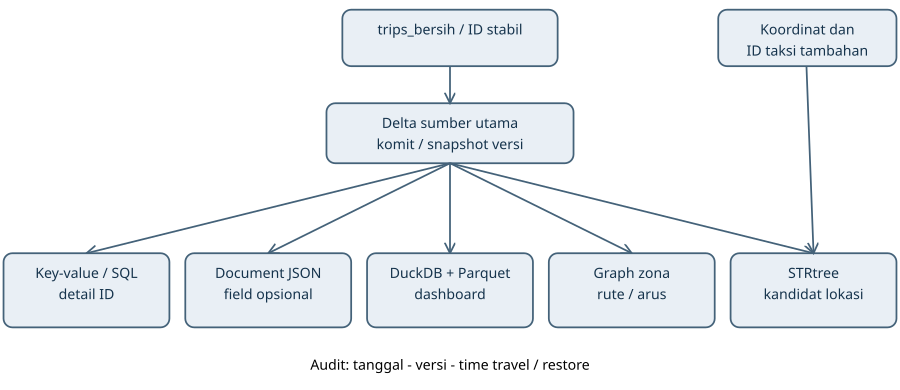

In [18]:
# Sel ini mendefinisikan studi kasus dan pembuat PDF; dipakai di notebook yang sama.
from xml.sax.saxutils import escape
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, PageBreak, Flowable
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from IPython.display import SVG

teks_sinkronisasi=(
    "Data ganda muncul pada detail key-value/document, tabel analitik, edge graph, dan indeks spasial. "
    "Delta dirancang sebagai sumber utama terversi; tiap proyeksi menyimpan source_version dan ID perjalanan stabil. "
    "Perubahan komit diproses melalui batch/change log dengan upsert idempoten, lalu checkpoint versi dipublikasikan "
    "setelah proyeksi selesai. Rekonsiliasi memeriksa jumlah/kunci/agregat terhadap snapshot sumber. Detail pembayaran "
    "dan audit membaca snapshot otoritatif; dashboard/rekomendasi boleh tertinggal sesuai SLA dan menampilkan versi/"
    "waktu pembaruan. Embedding wilayah memerlukan pembaruan salinan ketika referensi zona berubah. Desain ini belum "
    "diimplementasikan sebagai sistem terdistribusi dalam praktikum. ID praktikum dibuat pada sampel; ID produksi "
    "harus ditetapkan dan dipersistenkan sebelum semua proyeksi dibentuk."
)

def buat_tabel_studi_kasus():
    t_id=detik("cari 200 perjalanan - key-value")
    t_sql=detik("cari 200 perjalanan - SQL dengan indeks")
    t_duck=detik("DuckDB - hitung per wilayah (langsung dari Parquet)")
    t_bar=detik("SQLite - hitung per wilayah")
    t_g=detik("2 langkah - graph (NetworkX)");t_join=detik("2 langkah - SQL self-join (DuckDB)")
    t_np=detik("cara 2 - NumPy, 1000 kotak");t_idx=detik("cara 3 - STRtree, 1000 kotak")
    t_build=detik("bangun indeks STRtree")
    return pd.DataFrame([
      {"fitur":"1. Detail perjalanan berdasarkan ID","pilihan":"Key-value; SQLite berindeks sebagai alternatif",
       "alasan":f"200 ID: KV {t_id:.4f} s, SQLite berindeks {t_sql:.4f} s. Kunci langsung melayani satu perjalanan; untuk field opsional, nilai dapat berupa dokumen JSON.",
       "kelemahan":"Dict/TinyDB praktikum berada di memori dan bukan server produksi; ID sampel harus diganti ID stabil, dengan persistensi dan sinkronisasi."},
      {"fitur":"2. Dashboard pendapatan per wilayah per jam","pilihan":"DuckDB + Parquet berpartisi; Delta untuk data otoritatif",
       "alasan":f"Agregasi {len(df):,} baris: DuckDB {t_duck:.4f} s, SQLite {t_bar:.4f} s. Column pruning dan filter partisi mengurangi I/O; tanggal/jam dapat menjadi dimensi agregasi.",
       "kelemahan":"Benchmark K-4 merangkum wilayah, bukan seluruh query dashboard. Partisi tanggal perlu dirancang; banyak file kecil dan pembaruan proyeksi dapat menambah biaya."},
      {"fitur":"3. Tujuan populer dan rute dua/tiga langkah","pilihan":"Graph berarah berbobot arus antar zona",
       "alasan":f"Dua langkah: graph {t_g:.4f} s vs SQL {t_join:.4f} s; hasil sama {len(hg)} zona. Graph memudahkan traversal k dan ranking bobot arus.",
       "kelemahan":"Graph agregat kehilangan detail trip/waktu dan belum berarti rute jalan fisik. Kecepatan tidak selalu unggul; arus sintetis tidak membuktikan pola taksi nyata."},
      {"fitur":"4. Taksi yang menjemput dalam radius 500 m","pilihan":"Indeks spasial STRtree plus pemeriksaan jarak tepat",
       "alasan":f"K-6, 1.000 kotak: query STRtree {t_idx:.4f} s vs NumPy {t_np:.4f} s; bangun {t_build:.4f} s. Indeks menyaring kandidat lokasi sebelum predicate/jarak tepat.",
       "kelemahan":"Ini benchmark kotak pada titik sintetis, bukan radius 500 m. Perlu koordinat dan ID taksi nyata, CRS meter/jarak geodesik, lalu DISTINCT ID taksi."},
      {"fitur":"5. Audit/kembalikan tarif ke tanggal 1","pilihan":"Delta Lake: versi, time travel, restore",
       "alasan":f"K-7: v0 {bukti_k7['baris_v0']:,} baris, v1/v2 {bukti_k7['baris_v1']:,}; koreksi {bukti_k7['koreksi']:,} menaikkan total {bukti_k7['selisih']:.2f}. Append asing ditolak tanpa komit.",
       "kelemahan":"Versi harus dipetakan ke cutoff tanggal dan akses koreksi dibatasi. File historis memakan ruang; VACUUM terlalu dini menghilangkan kemampuan membaca versi lama."}
    ])

class DiagramAliran(Flowable):
    def __init__(self):
        super().__init__();self.width=510;self.height=220
    def draw(self):
        c=self.canv
        def kotak(x,y,w,h,lines,fill):
            c.setFillColor(colors.HexColor(fill));c.setStrokeColor(colors.HexColor('#446279'))
            c.roundRect(x,y,w,h,5,fill=1,stroke=1);c.setFillColor(colors.HexColor('#15334c'))
            c.setFont('Helvetica',8)
            for i,t in enumerate(lines):c.drawCentredString(x+w/2,y+h-14-i*11,t)
        def panah(x1,y1,x2,y2):
            c.setStrokeColor(colors.HexColor('#446279'));c.line(x1,y1,x2,y2)
            c.line(x2,y2,x2-3,y2+5);c.line(x2,y2,x2+3,y2+5)
        kotak(194,180,122,32,['trips_bersih / ID stabil'],'#e9eff5')
        kotak(407,180,101,32,['Koordinat dan','ID taksi tambahan'],'#fff0d8')
        kotak(185,125,140,34,['Delta sumber utama','komit / snapshot versi'],'#dceee8')
        panah(255,180,255,159)
        labels=[['Key-value / SQL','detail ID'],['Document JSON','field opsional'],['DuckDB + Parquet','dashboard'],['Graph zona','rute / arus'],['STRtree','kandidat lokasi']]
        for x,lines in zip([2,105,208,311,414],labels):
            kotak(x,40,94,42,lines,'#e9eff5');panah(255,125,x+47,82)
        panah(457,180,461,82)
        c.setFont('Helvetica',8);c.setFillColor(colors.HexColor('#446279'))
        c.drawCentredString(255,28,'Proyeksi ber-ID dan source_version; checkpoint setelah batch selesai')
        c.drawCentredString(255,12,'Audit: cutoff tanggal -> nomor versi -> time travel / RESTORE')

def buat_svg_diagram():
    boxes=[(2,'Key-value / SQL','detail ID'),(105,'Document JSON','field opsional'),(208,'DuckDB + Parquet','dashboard'),(311,'Graph zona','rute / arus'),(414,'STRtree','kandidat lokasi')]
    s='<svg xmlns="http://www.w3.org/2000/svg" width="900" height="390" viewBox="0 0 510 220"><defs><marker id="a" markerWidth="7" markerHeight="7" refX="6" refY="3" orient="auto"><path d="M0,0 L6,3 L0,6" fill="none" stroke="#446279"/></marker></defs><rect width="510" height="220" fill="white"/>'
    def boxsvg(x,y,w,h,a,b=''):
        return f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="5" fill="#e9eff5" stroke="#446279"/><text x="{x+w/2}" y="{y+14}" text-anchor="middle" font-family="sans-serif" font-size="8" fill="#15334c">{escape(a)}</text><text x="{x+w/2}" y="{y+26}" text-anchor="middle" font-family="sans-serif" font-size="8" fill="#15334c">{escape(b)}</text>'
    s+=boxsvg(194,5,122,32,'trips_bersih / ID stabil')+boxsvg(407,5,101,32,'Koordinat dan','ID taksi tambahan')+boxsvg(185,58,140,34,'Delta sumber utama','komit / snapshot versi')
    s+='<path d="M255,37 L255,58" stroke="#446279" marker-end="url(#a)"/>'
    for x,a,b in boxes:s+=f'<path d="M255,92 L{x+47},143" stroke="#446279" marker-end="url(#a)"/>'+boxsvg(x,143,94,42,a,b)
    s+='<path d="M457,37 L461,143" stroke="#446279" marker-end="url(#a)"/><text x="255" y="209" text-anchor="middle" font-size="8" font-family="sans-serif">Audit: tanggal - versi - time travel / restore</text></svg>'
    return s

def buat_laporan_pdf(path):
    path=Path(path)
    styles=getSampleStyleSheet()
    styles.add(ParagraphStyle(name='IsiP04',fontName='Helvetica',fontSize=9.2,leading=12.6,spaceAfter=7,textColor=colors.HexColor('#223749')))
    styles.add(ParagraphStyle(name='TabelP04',fontName='Helvetica',fontSize=8,leading=10.5,spaceAfter=0))
    styles.add(ParagraphStyle(name='JudulP04',fontName='Helvetica-Bold',fontSize=19,leading=23,spaceAfter=12,textColor=colors.HexColor('#15334c')))
    styles.add(ParagraphStyle(name='SubP04',fontName='Helvetica-Bold',fontSize=11.5,leading=15,spaceBefore=7,spaceAfter=9,textColor=colors.HexColor('#15334c')))
    def p(t,st='IsiP04'):return Paragraph(escape(str(t)),styles[st])
    def tabel(rows,widths):
        t=Table([[p(x,'TabelP04') for x in r] for r in rows],colWidths=widths,repeatRows=1,hAlign='LEFT')
        t.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,0),colors.HexColor('#dce7ef')),('VALIGN',(0,0),(-1,-1),'TOP'),
          ('GRID',(0,0),(-1,-1),.35,colors.HexColor('#c4d0da')),('LEFTPADDING',(0,0),(-1,-1),7),('RIGHTPADDING',(0,0),(-1,-1),7),
          ('TOPPADDING',(0,0),(-1,-1),7),('BOTTOMPADDING',(0,0),(-1,-1),7),('ROWBACKGROUNDS',(0,1),(-1,-1),[colors.white,colors.HexColor('#f6f8fa')])]))
        return t
    doc=SimpleDocTemplate(str(path),pagesize=A4,rightMargin=42,leftMargin=42,topMargin=44,bottomMargin=43)
    story=[p('Rancangan Penyimpanan Aplikasi Taksi','JudulP04'),p('Praktikum Big Data 4 - Studi Kasus P | Alfaris Aulia Rahman | 2411533006'),
      p(f'Sumber run: {SUMBER_DATA}. Dataset {len(df):,} baris; K-2/K-3 menggunakan sampel {len(sample):,}, TinyDB 20.000 awal. K-6 memakai 200.000 titik sintetis. Benchmark berasal dari notebook {JENIS_NOTEBOOK} pada {"Colab" if DI_COLAB else "kernel lokal baru"}.'),
      p('1. Pilihan untuk lima fitur','SubP04')]
    f=buat_tabel_studi_kasus();rows=[['Fitur dan pilihan','Alasan / angka benchmark','Kelemahan']]
    for r in f.to_dict('records'):rows.append([r['fitur']+'\n'+r['pilihan'],r['alasan'],r['kelemahan']])
    story+=[tabel(rows,[133,195,183]),Spacer(1,9),p('Angka adalah pengukuran pada satu proses, bukan perbandingan Redis, MongoDB, Neo4j, atau sistem terdistribusi. Dataset perjalanan sintetis, bila dipakai, hanya menguji cara menyimpan dan bertanya.')]
    story += [PageBreak(),p('Aliran Data dan Konsistensi Salinan','JudulP04'),p('2. Diagram rancangan','SubP04'),DiagramAliran(),
      p('Aliran di atas adalah rancangan produksi: Delta menyimpan snapshot otoritatif, sementara proyeksi melayani pola query masing-masing. Percobaan modul membangun model langsung dari trips_bersih; tidak mengimplementasikan pipeline sinkronisasi terdistribusi.'),
      p('3. Data ganda dan cara menjaga kesamaan','SubP04'),p(teks_sinkronisasi),
      p('4. Radius, identitas, dan waktu','SubP04'),p('Pencarian 500 meter membutuhkan koordinat jemput dan ID taksi yang tidak disediakan oleh percobaan ini. Bounding box/STRtree menyaring kandidat; jarak geodesik atau proyeksi dalam meter memastikan radius tepat. Hasil kemudian dihubungkan ke ID taksi dan dideduplikasi. Waktu K-6 hanya mendukung manfaat indeks pada query kotak, bukan SLA radius.'),
      p('Tanggal 1 untuk audit harus didefinisikan sebagai cutoff waktu/zona waktu dan dipetakan ke nomor versi Delta yang dicatat. Time travel membaca versi lama; restore menerbitkan keadaan versi itu sebagai komit baru sehingga riwayat tidak hilang. File historis harus dipertahankan selama periode audit.')]
    story += [PageBreak(),p('Bukti dan Batas Interpretasi','JudulP04'),p('5. Rekap bukti yang dipakai','SubP04')]
    r=buat_rekap();rr=[['Kebutuhan','Bukti','Interpretasi']]
    for x in r.to_dict('records'):rr.append([x['kebutuhan'],x['angka'],x['interpretasi']])
    story += [tabel(rr,[105,223,183]),Spacer(1,10),p('6. Batas pengukuran','SubP04'),
      p('Rasio dibandingkan hanya pada pasangan dengan populasi sama: KV vs SQL memakai sampel, sedangkan DuckDB vs SQLite memakai seluruh dataset. Waktu muat dan pembangunan indeks dipisahkan. Eksperimen K mengukur satu run; cache, versi pustaka, dan mesin memengaruhi angka. Graph dipilih karena pertanyaan keterhubungan, meskipun SQL dapat lebih cepat pada run tertentu.'),
      p('Dokumen fleksibel tetap memerlukan validasi aplikasi. ID sampel bukan ID taksi. Graph arus tidak sama dengan jaringan jalan fisik. Perbandingan kotak pada derajat tidak membuktikan akurasi radius meter, dan hasil data sintetis tidak mewakili pola perjalanan nyata.'),
      p('Acuan: Modul Praktikum Big Data - 04, bagian K, O, P dan R; benchmark_nosql.csv serta rekap_model_nosql.csv yang dihasilkan oleh run notebook ini. Catatan transaksi aktual disertakan dalam arsip Delta.')]
    def footer(c,d):
        c.setStrokeColor(colors.HexColor('#c4d0da'));c.line(42,32,A4[0]-42,32)
        c.setFont('Helvetica',8);c.setFillColor(colors.HexColor('#446279'))
        c.drawString(42,20,'BD P04 | 2411533006 | '+JENIS_NOTEBOOK)
        c.drawRightString(A4[0]-42,20,str(d.page))
    doc.build(story,onFirstPage=footer,onLaterPages=footer)
    Path(DIR_SIMPAN,'diagram_aliran.svg').write_text(buat_svg_diagram(),encoding='utf-8')
    return str(path)

display(SVG(buat_svg_diagram()))


In [19]:
display(buat_tabel_studi_kasus())
rekap=pd.DataFrame(catatan);rekap.to_csv(Path(DIR_SIMPAN)/"benchmark_nosql.csv",index=False)
buat_rekap().to_csv(Path(DIR_SIMPAN)/"rekap_model_nosql.csv",index=False)
laporan_r=buat_laporan_pdf(Path(DIR_SIMPAN)/"laporan_rancangan_P04.pdf")
arsip_k=shutil.make_archive(str(WORKDIR/"delta_benchmark_arsip"),"zip",root_dir=Path(PATH_DELTA).parent,base_dir=Path(PATH_DELTA).name)
shutil.copy2(arsip_k,Path(DIR_SIMPAN)/"trips_delta_benchmark.zip")
for nama in ("trips_delta.zip","trips_delta_benchmark.zip"):
    with zipfile.ZipFile(Path(DIR_SIMPAN)/nama) as z:assert z.testzip() is None
validasi={"sumber_data":SUMBER_DATA,"baris":len(df),"snapshot_hari1_identik":True,
 "delta_versi_dua_hari":DeltaTable(PATH_DUA_HARI).version(),"baris_hari1":len(baca_hari1),
 "baris_hari2":len(sesudah_koreksi),"jumlah_koreksi":jumlah_koreksi,
 "lingkungan":"Colab" if DI_COLAB else "kernel lokal baru","python":sys.version,
 "pustaka":{m:getattr(importlib.import_module(m),"__version__","tersedia") for m in paket},
 "waktu_utc":pd.Timestamp.now("UTC").isoformat(),"jenis_notebook":"tugas R"}
Path(DIR_SIMPAN,"validasi_run.json").write_text(json.dumps(validasi,indent=2),encoding="utf-8")
print("R-1 sampai R-4 selesai; keluaran:",DIR_SIMPAN)
print("PDF:",laporan_r)
con.close();con_s.close();con_d.close();db.close()

,fitur,pilihan,alasan,kelemahan
0,1. Detail perjalanan berdasarkan ID,Key-value; SQLite berindeks sebagai alternatif,"200 ID: KV 0.0011 s, SQLite berindeks 0.0048 s...",Dict/TinyDB praktikum berada di memori dan buk...
1,2. Dashboard pendapatan per wilayah per jam,DuckDB + Parquet berpartisi; Delta untuk data ...,"Agregasi 1,000,000 baris: DuckDB 0.0319 s, SQL...","Benchmark K-4 merangkum wilayah, bukan seluruh..."
2,3. Tujuan populer dan rute dua/tiga langkah,Graph berarah berbobot arus antar zona,Dua langkah: graph 0.0173 s vs SQL 0.0055 s; h...,Graph agregat kehilangan detail trip/waktu dan...
3,4. Taksi yang menjemput dalam radius 500 m,Indeks spasial STRtree plus pemeriksaan jarak ...,"K-6, 1.000 kotak: query STRtree 0.2964 s vs Nu...","Ini benchmark kotak pada titik sintetis, bukan..."
4,5. Audit/kembalikan tarif ke tanggal 1,"Delta Lake: versi, time travel, restore","K-7: v0 100,000 baris, v1/v2 150,000; koreksi ...",Versi harus dipetakan ke cutoff tanggal dan ak...


R-1 sampai R-4 selesai; keluaran: /content/drive/MyDrive/BigData/Praktikum4/Tugas
PDF: /content/drive/MyDrive/BigData/Praktikum4/Tugas/laporan_rancangan_P04.pdf
